# Параметрическая оптимизация трёхступенчатой ТВД

Ноутбук использует **существующую** модель проекта:
`Turbinis-Cycle/Turbinis-Cycle.ipynb` (цикл) и
`Turbinis-Calc/Main_Turbinis_Calc_Book.ipynb` (поступенчатый расчёт, п. 1–153).

Новая физическая модель не создаётся. Ядро `optimizer_core.py` исполняет те же ячейки
блокнота, что и рабочий расчёт, добавляя пересчёт цикла, валидацию, поиск и экспорт.

**Главное правило:** все числа в таблицах получаются фактическим запуском модели.
Если допустимого решения нет — это показывается явно, без подгонки.


## 1. Введение

Исходная точка: T*г = 1250 К, N = 110 кВт, π*к = 11, G ≈ 0.562 кг/с, z = 3.
Цель — найти параметры, удовлетворяющие жёстким ограничениям книги и проекта,
и максимизировать l_с1. Режимы:

* **A** — фиксированный цикл (π*к = 11, N = 110 кВт);
* **B** — параметрическое исследование цикла (π*к — переменная, цикл пересчитывается);
* **C** — масштабирование (N — переменная, расход и геометрия пересчитываются).

Ограничения разделены на `hard` (физика/проект), `project` (компоновка) и `target`
(желаемые l_с1 ≥ 20 мм, η*т ≥ 0.90).


## 2. Загрузка модели и исходные данные

In [1]:
%matplotlib inline
import json, sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, str(Path.cwd()))
import optimizer_core as oc

warnings.filterwarnings("ignore")
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)
print("Ядро:", oc.__file__)


Ядро: /home/jovyan/work/Turbinis-Curs/Optimizer/optimizer_core.py


In [2]:
m = oc.load_model()
print("Ячеек в блокноте:", len(m.nb["cells"]))
print("Ячейка параметров:", m.param_idx, "| ядро:", m.core_idx, "| полный расчёт:", m.full_idx)
print("Исправлен итератор расхода G:", m.patched)
print("Цикл: π*к =", m.cycle["π_к_выб"], "| G =", round(m.cycle["G_в_выб"], 4), "кг/с | N =", m.cycle["N_зад"] / 1e3, "кВт")


Ячеек в блокноте: 34
Ячейка параметров: 5 | ядро: [7, 9, 12, 14, 16, 20] | полный расчёт: [22, 24, 26]
Исправлен итератор расхода G: True
Цикл: π*к = 11.0 | G = 0.5889 кг/с | N = 110.0 кВт


In [3]:
bc = oc.cycle_point(m, pi=11.0, T_g=1250.0, N=110000.0)
df_in = pd.DataFrame([
    ("T*г", "К", 1250.0, "цикл"),
    ("N на валу", "кВт", 110.0, "цикл"),
    ("π*к", "-", bc["pi"], "цикл, зафиксирована"),
    ("G_в", "кг/с", bc["G"], "цикл"),
    ("p*г", "кПа", bc["p_g"] / 1e3, "цикл"),
    ("p_т", "кПа", bc["p_t"] / 1e3, "цикл"),
    ("π*т", "-", bc["p_g"] / bc["p_t"], "цикл"),
    ("T*т", "К", bc["T_t"], "цикл"),
    ("L_т", "кДж/кг", bc["L_t"] / 1e3, "цикл"),
    ("C_e", "кг/(кВт·ч)", bc["C_e"], "цикл"),
], columns=["величина", "ед.", "значение", "источник"])
display(df_in.style.hide(axis="index"))


величина,ед.,значение,источник
T*г,К,1250.000000,цикл
N на валу,кВт,110.000000,цикл
π*к,-,11.000000,"цикл, зафиксирована"
G_в,кг/с,0.588934,цикл
p*г,кПа,1048.333440,цикл
p_т,кПа,106.365000,цикл
π*т,-,9.856000,цикл
T*т,К,730.130920,цикл
L_т,кДж/кг,552.874722,цикл
C_e,кг/(кВт·ч),0.324548,цикл


## 3. Математическая модель

Используются формулы существующего блокнота:

* неразрывность: `l = G·v / (π·D·c_a)`, `A = π·D·l`;
* треугольники: `w1² = c1² + u1² − 2·c1·u1·cos α1`, `w2 = ψ·√(w1² + 2H_л + u2² − u1²)`;
* `c2a = κ·c1a`, `α2 = atan2(c2a, c2u)`, `L_u = u·(c1u + c2u)`;
* потери: `h_c`, `h_л`, `h_в`, зазор `h_з`, трение `h_тв` (п. 103–121);
* ρ_ср — по таблице стр. 58 от `l_л/D_ср`, с проверкой ρ у корня;
* прочность: `σ_р = k_n·n²·A_лa`, `n = √(σ_л/(k_n·A_т))`.

Источник: Михальцев В.Е., Моляков В.Д., ч. 1, п. 1–153 и гл. 6–8.


## 4. Настройка оптимизации

Меняйте блок ниже. Для быстрого прогона оставьте `QUICK = True`.


In [4]:
CONFIG = {
    "mode": "A",              # A / B / C
    "vary_kappa": True,
    "vary_sigma": True,
    "vary_tg": False,         # T*г как переменная (для скрипта обратной оптимизации)
    "phi": 0.97,              # для режима A (как в рабочем блокноте)
    "psi": 0.96,
    "pi": 11.0,
    "T_g": 1250.0,
    "N": 110000.0,
    "lc1_target": 0.020,
    "eta_target": 0.90,
    "seed": 1,
    "quick": True,
}
QUICK = CONFIG["quick"]
N_RANDOM = 24 if QUICK else 80
DE_MAXITER = 3 if QUICK else 12
DE_POPSIZE = 3 if QUICK else 6
LOCAL_STEPS = 1 if QUICK else 3

b = oc.границы(dict(CONFIG))
df_b = pd.DataFrame({"переменная": oc._имена(dict(CONFIG)), "min": b[:, 0], "max": b[:, 1]})
display(df_b.style.hide(axis="index"))
print("QUICK =", QUICK, "| DE:", DE_MAXITER, "x", DE_POPSIZE, "| локальных шагов:", LOCAL_STEPS)


переменная,min,max
D1,0.500000,1.000000
D2,0.600000,1.000000
lD,0.200000,0.333333
a11,9.000000,20.000000
a12,9.000000,20.000000
a13,10.000000,24.000000
w1,0.600000,1.200000
w2,0.600000,1.200000
k1,0.950000,1.400000
k2,0.950000,1.300000


QUICK = True | DE: 3 x 3 | локальных шагов: 1


## 5. Проверка исходной модели

Сравниваем расчёт ядра с текущим рабочим блокнотом. Ожидаемые значения из блокнота:
l_с1 ≈ 17.8 мм, α₂ ≈ 21.7/82.7/90.5°, π ≈ 2.20/2.16/2.37, N = 110 кВт.

> В оптимизаторе α₂ 1-й ступени — строго **70…90°** (стр. 38). Старое проектное
> ослабление 20…90° здесь не применяется: исходный вариант 21.7° честно показывается
> как недопустимый.


In [5]:
cfg0 = dict(CONFIG)
cfg0.update(mode="A", phi=0.97, psi=0.96, pi=11.0, T_g=1250.0, N=110000.0)
x0 = oc.warm_start(cfg0)
res0 = oc.evaluate(x0, m, cfg0, full=True)
chk0 = oc.validate(res0, cfg0, full=True)
df0 = pd.DataFrame([
    ("l_с1, мм", 17.8, res0["lc1"] * 1e3),
    ("α2 ст.1, °", 21.7, res0["a2"][0]),
    ("α2 ст.2, °", 82.7, res0["a2"][1]),
    ("α2 ст.3, °", 90.5, res0["a2"][2]),
    ("π ст.1", 2.20, res0["pi"][0]),
    ("π ст.2", 2.16, res0["pi"][1]),
    ("π ст.3", 2.37, res0["pi"][2]),
    ("N, кВт", 110.0, res0["N_val"] / 1e3),
], columns=["величина", "блокнот", "ядро оптимизатора"])
df0["расхождение"] = df0["ядро оптимизатора"] - df0["блокнот"]
display(df0.style.format({"блокнот": "{:.3f}", "ядро оптимизатора": "{:.3f}", "расхождение": "{:+.3f}"}).hide(axis="index"))
print("Исходный вариант: l_с1 =", round(res0["lc1"]*1e3, 2), "мм; α2 =", [round(v,1) for v in res0["a2"]])
print("Полная валидация исходного варианта:")
display(oc.checks_table(chk0).style.hide(axis="index"))


величина,блокнот,ядро оптимизатора,расхождение
"l_с1, мм",17.800,17.789,-0.011
"α2 ст.1, °",21.700,21.717,+0.017
"α2 ст.2, °",82.700,82.723,+0.023
"α2 ст.3, °",90.500,90.503,+0.003
π ст.1,2.200,2.196,-0.004
π ст.2,2.160,2.158,-0.002
π ст.3,2.370,2.373,+0.003
"N, кВт",110.000,110.000,-0.000


Исходный вариант: l_с1 = 17.79 мм; α2 = [21.7, 82.7, 90.5]
Полная валидация исходного варианта:


проверка,значение,допуск,тип,статус
z = 3,3,3,hard,OK
D1 <= D2 <= D3=1,0.670/1.000/1.000,"не убывают, D3=1",project,OK
l_т/D_т <= 1/3,0.2506,<= 0.3333,project,OK
α1 ст.1 >= 11°,9.25°,>= 11°,hard,НЕ выполнено
α1 ст.2 >= 11°,11.00°,>= 11°,hard,OK
α1 ст.3 >= 11°,19.00°,>= 11°,hard,OK
α2 ст.1 ∈ [70; 90]°,21.72°,[70; 90]°,hard,НЕ выполнено
α2 ст.2 ∈ [70; 90]°,82.72°,[70; 90]°,hard,OK
α2 ст.3 ∈ [80; 90]°,90.50°,[80; 90]°,hard,НЕ выполнено
α2 не более 90° (все ступени),21.7/82.7/90.5,<= 90°,hard,НЕ выполнено


## 6. Предварительный параметрический анализ

Одномерные зависимости от `D1`, `l_т/D_т`, `α1` 1-й ступени и веса π 1-й ступени.
Красные линии — границы α2 70/90°, зелёная — l_с1 = 20 мм.


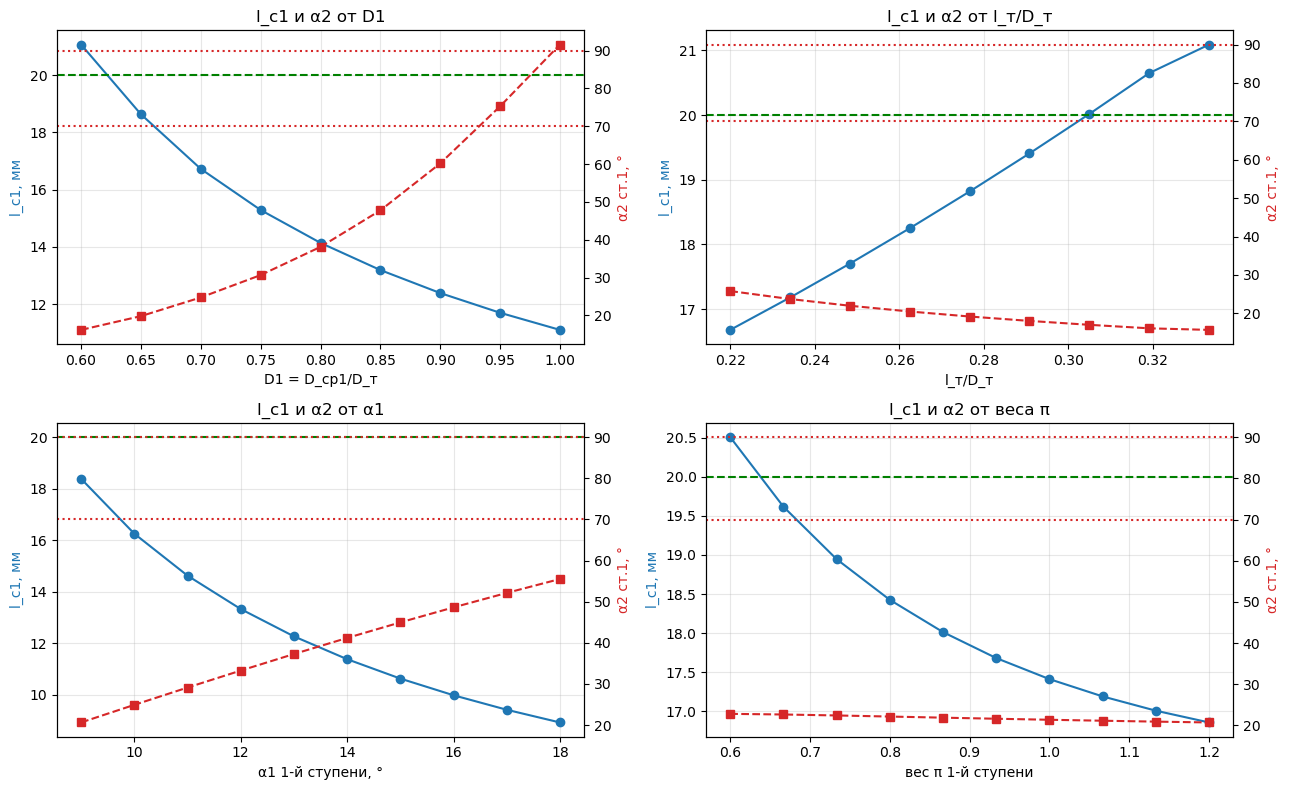

,x,lc1,a21,a22,a23,eta,N
0,0.60,21.06,16.19,80.28,88.58,0.90,110.0
1,0.65,18.63,19.82,82.05,89.97,0.90,110.0
2,0.70,16.72,24.76,83.61,91.21,0.91,110.0
3,0.75,15.28,30.67,84.82,92.16,0.91,110.0
4,0.80,14.14,38.12,85.73,92.88,0.91,110.0
5,0.85,13.19,47.77,86.38,93.40,0.91,110.0
6,0.90,12.38,60.18,86.80,93.73,0.91,110.0
7,0.95,11.69,75.27,87.00,93.90,0.91,110.0
8,1.00,11.10,91.59,87.00,93.91,0.91,110.0


,x,lc1,a21,a22,a23,eta,N
0,0.22,16.68,25.80,106.67,105.55,0.91,110.0
1,0.23,17.18,23.72,95.45,98.60,0.91,110.0
2,0.25,17.70,21.97,84.41,91.61,0.91,110.0
3,0.26,18.25,20.47,74.29,84.75,0.91,110.0
4,0.28,18.82,19.17,65.51,78.19,0.90,110.0
5,0.29,19.41,18.02,58.16,72.07,0.90,110.0
6,0.30,20.02,17.00,52.11,66.43,0.90,110.0
7,0.32,20.65,16.09,47.15,61.30,0.90,110.0
8,0.33,21.09,15.68,43.12,56.75,0.90,110.0


In [6]:
cfg_plot = dict(cfg0)

def sweep(name, values, cfg):
    idx = oc._имена(cfg).index(name)
    xb = oc.warm_start(cfg)
    rows = []
    for v in values:
        x = xb.copy(); x[idx] = float(v)
        try:
            r = oc.evaluate(x, m, cfg)
            rows.append({"x": float(v), "lc1": r["lc1"]*1e3, "a21": r["a2"][0], "a22": r["a2"][1],
                         "a23": r["a2"][2], "eta": r["eta"], "N": r["N_val"]/1e3})
        except Exception:
            pass
    return pd.DataFrame(rows)

sD = sweep("D1", np.linspace(0.60, 1.00, 9), cfg_plot)
sL = sweep("lD", np.linspace(0.22, 1/3, 9), cfg_plot)
sA = sweep("a11", np.linspace(9.0, 18.0, 10), cfg_plot)
sW = sweep("w1", np.linspace(0.60, 1.20, 10), cfg_plot)

fig, ax = plt.subplots(2, 2, figsize=(13, 8))
for a, df, xlab, ttl in [
    (ax[0,0], sD, "D1 = D_ср1/D_т", "l_с1 и α2 от D1"),
    (ax[0,1], sL, "l_т/D_т", "l_с1 и α2 от l_т/D_т"),
    (ax[1,0], sA, "α1 1-й ступени, °", "l_с1 и α2 от α1"),
    (ax[1,1], sW, "вес π 1-й ступени", "l_с1 и α2 от веса π"),
]:
    if df.empty: continue
    a.plot(df["x"], df["lc1"], "o-", color="tab:blue", label="l_с1, мм")
    a.axhline(20, color="green", ls="--", label="l_с1 = 20 мм")
    a.set_xlabel(xlab); a.set_ylabel("l_с1, мм", color="tab:blue"); a.grid(alpha=.3)
    a2 = a.twinx()
    a2.plot(df["x"], df["a21"], "s--", color="tab:red", label="α2 ст.1")
    a2.axhline(70, color="tab:red", ls=":"); a2.axhline(90, color="tab:red", ls=":")
    a2.set_ylabel("α2 ст.1, °", color="tab:red")
    a.set_title(ttl)
fig.tight_layout()
plt.savefig(oc.ПАПКА_РЕЗУЛЬТАТОВ / "parametric_1d.png", dpi=140)
plt.show()
display(sD.round(2)); display(sL.round(2))


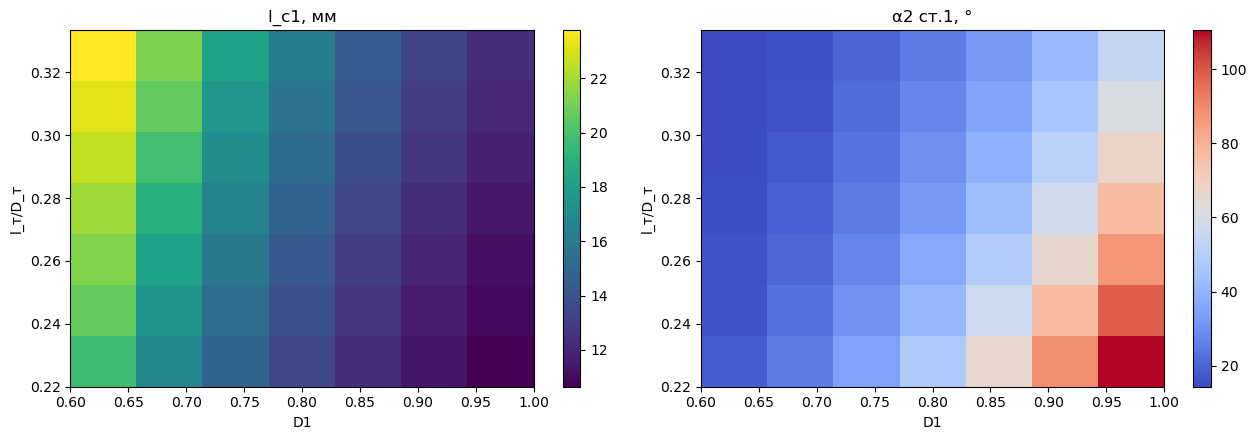

In [7]:
# Тепловая карта: l_с1 и α2 ст.1 по D1 и l_т/D_т
d1v = np.linspace(0.60, 1.00, 7)
ldv = np.linspace(0.22, 1/3, 7)
Z_lc = np.full((len(ldv), len(d1v)), np.nan)
Z_a2 = np.full((len(ldv), len(d1v)), np.nan)
iD = oc._имена(cfg_plot).index("D1"); iL = oc._имена(cfg_plot).index("lD")
xb = oc.warm_start(cfg_plot)
for i, ld in enumerate(ldv):
    for j, d1 in enumerate(d1v):
        x = xb.copy(); x[iD] = d1; x[iL] = ld
        try:
            r = oc.evaluate(x, m, cfg_plot)
            Z_lc[i, j] = r["lc1"] * 1e3
            Z_a2[i, j] = r["a2"][0]
        except Exception:
            pass
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
im0 = ax[0].imshow(Z_lc, origin="lower", aspect="auto", extent=[d1v[0], d1v[-1], ldv[0], ldv[-1]], cmap="viridis")
ax[0].set_xlabel("D1"); ax[0].set_ylabel("l_т/D_т"); ax[0].set_title("l_с1, мм")
fig.colorbar(im0, ax=ax[0])
im1 = ax[1].imshow(Z_a2, origin="lower", aspect="auto", extent=[d1v[0], d1v[-1], ldv[0], ldv[-1]], cmap="coolwarm")
ax[1].set_xlabel("D1"); ax[1].set_ylabel("l_т/D_т"); ax[1].set_title("α2 ст.1, °")
fig.colorbar(im1, ax=ax[1])
fig.tight_layout()
plt.savefig(oc.ПАПКА_РЕЗУЛЬТАТОВ / "heatmap_D1_lD.png", dpi=140)
plt.show()


## 7. Глобальная оптимизация (режим A, жёсткие ограничения)

Дифференциальная эволюция по D1, D2, l_т/D_т, α1, весам π, κ и σ_л.
Если допустимых решений нет — это ожидаемый результат при N = 110 кВт.


In [8]:
cfgA = dict(CONFIG)
archA = oc.run_global(m, cfgA, maxiter=DE_MAXITER, popsize=DE_POPSIZE, seed=CONFIG["seed"], full=False)
rows = archA.rows
n_ok = sum(1 for r in rows if r["res"] is not None)
n_feas = sum(1 for r in rows if r["feasible"])
n_strict = sum(1 for r in rows if r["strict"])
print(f"оценено: {len(rows)} | с расчётом: {n_ok} | допустимых: {n_feas} | строго всех: {n_strict}")
bestA = archA.best()
if bestA["res"] is not None:
    print("лучший score:", round(bestA["score"], 4), "| l_с1 =", round(bestA["res"]["lc1"]*1e3, 2), "мм")
    print("α2 =", [round(v,1) for v in bestA["res"]["a2"]], "| π =", [round(v,2) for v in bestA["res"]["pi"]])
    print("нарушено:", [c["name"] for c in bestA["checks"] if not c["ok"] and c["kind"] in ("hard","project")])
else:
    print("все попытки завершились ошибкой модели")


оценено: 144 | с расчётом: 142 | допустимых: 0 | строго всех: 0
лучший score: 60.4165 | l_с1 = 9.73 мм
α2 = [76.8, 75.8, 78.9] | π = [1.86, 2.41, 2.4]
нарушено: ['α2 ст.3 ∈ [80; 90]°', 'π ст.2 ∈ [1.8; 2.4]', 'π ст.3 ∈ [1.8; 2.4]', 'длины лопаток не убывают', 'l_с1 >= 14 мм (проект)']


## 8. Локальная доводка

In [9]:
xloc, sc_loc, archL = oc.run_local(m, cfgA, x0=(bestA["res"]["x"] if bestA["res"] else None),
                                    steps=LOCAL_STEPS, seed=CONFIG["seed"], full=False)
archAll = oc.Archive(); archAll.rows = rows + archL.rows
best = archAll.best()
print("локальная доводка: score =", round(sc_loc, 4))
if best["res"] is not None:
    print("l_с1 =", round(best["res"]["lc1"]*1e3, 2), "мм | α2 =", [round(v,1) for v in best["res"]["a2"]],
          "| η*т =", round(best["res"]["eta"], 4))
    print("статус:", "строго допустим" if best["strict"] else ("допустим" if best["feasible"] else "недопустим"))


локальная доводка: score = 39.0235
l_с1 = 10.08 мм | α2 = [70.1, 79.4, 83.6] | η*т = 0.9072
статус: недопустим


## 9. Многокритериальная оптимизация (Pareto)

Недоминируемые решения по (max l_с1, max η*т, min σ_max, min потери).


Pareto-точек: 28


"l_с1, мм",η*т,"σ_max, МПа",потери,D1,lD,α2.1,допустим
17.8,0.9063,290,0.0937,0.670000,0.250586,21.716598,False
25.6,0.8899,363,0.1101,0.519796,0.261245,15.025953,False
19.3,0.8707,295,0.1293,0.516946,0.289959,16.656115,False
17.5,0.8609,281,0.1391,0.522994,0.225573,20.329331,False
10.3,0.8962,255,0.1038,0.559053,0.212478,36.412420,False
8.9,0.9111,253,0.0889,0.714732,0.220846,49.587616,False
12.7,0.9137,278,0.0863,0.835153,0.221832,46.649152,False
13.4,0.9141,354,0.0859,0.873323,0.265719,46.029726,False
19.4,0.9052,363,0.0948,0.600602,0.277128,14.542346,False
15.7,0.8891,255,0.1109,0.884411,0.282120,29.446102,False


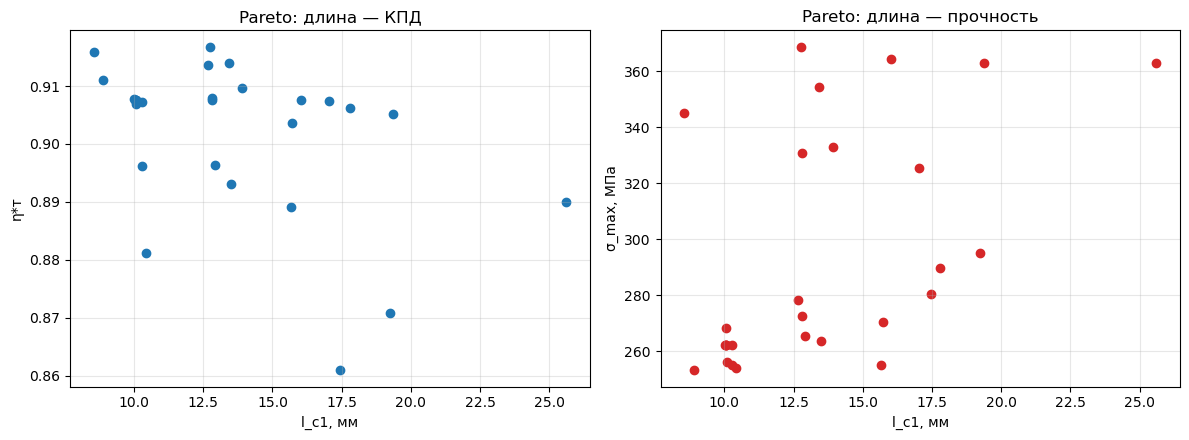

In [10]:
pf = oc.pareto(archAll.rows)
print("Pareto-точек:", len(pf))
if pf:
    dfp = pd.DataFrame([{
        "l_с1, мм": r["res"]["lc1"]*1e3, "η*т": r["res"]["eta"],
        "σ_max, МПа": r["res"]["sigma_max"], "потери": r["res"]["loss"],
        "D1": r["res"]["p"]["D"][0], "lD": r["res"]["p"]["lD"],
        "α2.1": r["res"]["a2"][0], "допустим": r["feasible"],
    } for r in pf])
    display(dfp.style.format({"l_с1, мм": "{:.1f}", "η*т": "{:.4f}", "σ_max, МПа": "{:.0f}", "потери": "{:.4f}"}).hide(axis="index"))
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    ax[0].scatter([r["res"]["lc1"]*1e3 for r in pf], [r["res"]["eta"] for r in pf], c="tab:blue")
    ax[0].set_xlabel("l_с1, мм"); ax[0].set_ylabel("η*т"); ax[0].set_title("Pareto: длина — КПД"); ax[0].grid(alpha=.3)
    ax[1].scatter([r["res"]["lc1"]*1e3 for r in pf], [r["res"]["sigma_max"] for r in pf], c="tab:red")
    ax[1].set_xlabel("l_с1, мм"); ax[1].set_ylabel("σ_max, МПа"); ax[1].set_title("Pareto: длина — прочность"); ax[1].grid(alpha=.3)
    fig.tight_layout(); plt.savefig(oc.ПАПКА_РЕЗУЛЬТАТОВ / "pareto.png", dpi=140); plt.show()
else:
    print("Pareto-фронт не построен: нет расчётных решений.")


## 10. Итоговые результаты

Таблицы по трём ступеням и полный список проверок для лучшего найденного варианта.


In [11]:
res_best = best["res"] if best["res"] is not None else res0
chk_best = oc.validate(res_best, cfgA if res_best is not res0 else cfg0, full=True)
display(oc.stages_table(res_best).style.format("{:.3f}"))
df_over = pd.DataFrame([
    ("N на валу, кВт", res_best["N_val"]/1e3),
    ("η*т", res_best["eta"]),
    ("G_в, кг/с", res_best["cycle"]["G"]),
    ("n, об/мин", res_best["n_t"]),
    ("D_т, мм", res_best["D_t"]*1e3),
    ("σ_max, МПа", res_best["sigma_max"]),
    ("l_с1, мм", res_best["lc1"]*1e3),
    ("C_e, кг/(кВт·ч)", res_best["cycle"]["C_e"]),
    ("η_e цикла", res_best["cycle"]["eta_e"]),
], columns=["величина", "значение"])
display(df_over.style.format({"значение": "{:.4g}"}).hide(axis="index"))
display(oc.checks_table(chk_best).style.hide(axis="index"))


Ступень,1,2,3
"D_ср, мм",87.451,93.203,99.946
"u, м/с",324.739,346.100,371.138
"l_с, мм",10.076,11.778,21.370
"l_л, мм",10.255,11.113,24.427
"α1, °",11.049,15.296,16.281
"α2, °",70.055,79.448,83.629
"β1, °",26.395,35.221,55.231
"β2, °",17.694,27.389,22.022
ρ,0.250,0.261,0.393
π,1.883,2.389,2.380


величина,значение
"N на валу, кВт",110
η*т,0.9072
"G_в, кг/с",0.5889
"n, об/мин",7.092e+04
"D_т, мм",99.95
"σ_max, МПа",262.3
"l_с1, мм",10.08
"C_e, кг/(кВт·ч)",0.3245
η_e цикла,0.2571


проверка,значение,допуск,тип,статус
z = 3,3,3,hard,OK
D1 <= D2 <= D3=1,0.875/0.933/1.000,"не убывают, D3=1",project,OK
l_т/D_т <= 1/3,0.2444,<= 0.3333,project,OK
α1 ст.1 >= 11°,11.05°,>= 11°,hard,OK
α1 ст.2 >= 11°,15.30°,>= 11°,hard,OK
α1 ст.3 >= 11°,16.28°,>= 11°,hard,OK
α2 ст.1 ∈ [70; 90]°,70.06°,[70; 90]°,hard,OK
α2 ст.2 ∈ [70; 90]°,79.45°,[70; 90]°,hard,OK
α2 ст.3 ∈ [80; 90]°,83.63°,[80; 90]°,hard,OK
α2 не более 90° (все ступени),70.1/79.4/83.6,<= 90°,hard,OK


## 11. Сравнение вариантов

In [12]:
def строка(имя, r):
    return {"вариант": имя, "l_с1, мм": r["lc1"]*1e3, "α2.1, °": r["a2"][0],
            "η*т": r["eta"], "σ_max, МПа": r["sigma_max"], "N, кВт": r["N_val"]/1e3,
            "π*к": r["cycle"]["pi"], "G, кг/с": r["cycle"]["G"]}

варики = [строка("исходный (110 кВт)", res0)]
feas = [r for r in archAll.rows if r["feasible"] and r["res"] is not None]
if feas:
    варики.append(строка("max l_с1 (допустимый)", max(feas, key=lambda r: r["res"]["lc1"])["res"]))
    варики.append(строка("max η*т (допустимый)", max(feas, key=lambda r: r["res"]["eta"])["res"]))
    варики.append(строка("лучший score", min(feas, key=lambda r: r["score"])["res"]))
else:
    варики.append({"вариант": "допустимых при 110 кВт нет", "l_с1, мм": np.nan, "α2.1, °": np.nan,
                   "η*т": np.nan, "σ_max, МПа": np.nan, "N, кВт": np.nan, "π*к": 11, "G, кг/с": np.nan})
display(pd.DataFrame(варики).style.format({"l_с1, мм": "{:.1f}", "α2.1, °": "{:.1f}", "η*т": "{:.4f}",
                                          "σ_max, МПа": "{:.0f}", "N, кВт": "{:.1f}", "π*к": "{:.2f}",
                                          "G, кг/с": "{:.3f}"}).hide(axis="index"))


вариант,"l_с1, мм","α2.1, °",η*т,"σ_max, МПа","N, кВт",π*к,"G, кг/с"
исходный (110 кВт),17.8,21.7,0.9063,290,110.0,11.00,0.589
допустимых при 110 кВт нет,nan,nan,nan,nan,nan,11.00,nan


## 12. Экспорт результатов

In [13]:
out = oc.ПАПКА_РЕЗУЛЬТАТОВ
# архив
pd.DataFrame([{
    "score": r["score"], "feasible": r["feasible"], "strict": r["strict"],
    "l_c1_mm": r["res"]["lc1"]*1e3 if r["res"] else np.nan,
    "eta": r["res"]["eta"] if r["res"] else np.nan,
    "sigma_max": r["res"]["sigma_max"] if r["res"] else np.nan,
    "N_kW": r["res"]["N_val"]/1e3 if r["res"] else np.nan,
    "a2_1": r["res"]["a2"][0] if r["res"] else np.nan,
    "pi_k": r["res"]["cycle"]["pi"] if r["res"] else np.nan,
} for r in archAll.rows]).to_csv(out / "archive.csv", index=False)
# итоговые таблицы
with pd.ExcelWriter(out / "optimization_tables.xlsx") as w:
    oc.stages_table(res_best).to_excel(w, sheet_name="Ступени")
    oc.checks_table(chk_best).to_excel(w, sheet_name="Проверки", index=False)
    df_over.to_excel(w, sheet_name="Турбина", index=False)
oc.save_json(out / "best_config.json", {"config": {k: v for k, v in CONFIG.items()},
                                        "x": res_best["x"].tolist(), "result": {k: res_best[k] for k in
                                        ("lc1", "a2", "pi", "N_val", "eta", "sigma_max", "D_t", "n_t")}})
print("сохранено в", out)


сохранено в /home/jovyan/work/Turbinis-Curs/Optimizer/results


## 13. Обратная оптимизация исходных параметров цикла

Если при N = 110 кВт строго допустимого решения нет, задача — найти минимальные
изменения цикла. Ниже запускается режим C (масштабирование N) с той же моделью.
Скрипт `optimize_initial_conditions.py` делает то же отдельно, с внешним поиском
по π*к, T*г и N.


In [14]:
need_scaling = not any(r["strict"] for r in archAll.rows)
print("нужна обратная оптимизация:", need_scaling)
resC = None; chkC = None
if need_scaling:
    cfgC = dict(CONFIG)
    cfgC.update(mode="C", phi=0.965, psi=0.95, pi=11.0, T_g=1250.0, N=450000.0)
    xwC = oc.warm_start(cfgC)
    xC, scC, archC = oc.run_local(m, cfgC, x0=xwC, steps=LOCAL_STEPS, seed=CONFIG["seed"], full=False)
    resC = oc.evaluate(xC, m, cfgC, full=True)
    chkC = oc.validate(resC, cfgC, full=True)
    print("вариант масштабирования: N =", resC["N_val"]/1e3, "кВт | G =", round(resC["cycle"]["G"], 3), "кг/с")
    print("l_с1 =", round(resC["lc1"]*1e3, 2), "мм | α2 =", [round(v,1) for v in resC["a2"]],
          "| π =", [round(v,2) for v in resC["pi"]], "| η*т =", round(resC["eta"], 4))
    display(oc.stages_table(resC).style.format("{:.3f}"))
    display(oc.checks_table(chkC).style.hide(axis="index"))
    df_sc = pd.DataFrame([
        ("π*к", 11.0, resC["cycle"]["pi"]),
        ("T*г, К", 1250.0, resC["cycle"]["T_g"]),
        ("N, кВт", 110.0, resC["N_val"]/1e3),
        ("G, кг/с", res0["cycle"]["G"], resC["cycle"]["G"]),
        ("p*г, кПа", res0["cycle"]["p_g"]/1e3, resC["cycle"]["p_g"]/1e3),
        ("η*т", res0["eta"], resC["eta"]),
        ("l_с1, мм", res0["lc1"]*1e3, resC["lc1"]*1e3),
        ("α2.1, °", res0["a2"][0], resC["a2"][0]),
        ("σ_max, МПа", res0["sigma_max"], resC["sigma_max"]),
        ("C_e, кг/(кВт·ч)", res0["cycle"]["C_e"], resC["cycle"]["C_e"]),
    ], columns=["параметр", "исходный цикл", "масштабирование"])
    df_sc["изменение, %"] = (df_sc["масштабирование"] / df_sc["исходный цикл"] - 1) * 100
    display(df_sc.style.format({"исходный цикл": "{:.4g}", "масштабирование": "{:.4g}", "изменение, %": "{:+.1f}"}).hide(axis="index"))
    oc.save_json(out / "scaling_solution.json", {"config": cfgC, "x": xC.tolist(),
        "result": {k: resC[k] for k in ("lc1", "a2", "pi", "N_val", "eta", "sigma_max", "D_t", "n_t", "gamma_max", "rho_root", "lambda_c1")}})
else:
    print("строго допустимое решение уже найдено в режиме A.")


нужна обратная оптимизация: True


вариант масштабирования: N = 449.9999946845387 кВт | G = 2.409 кг/с
l_с1 = 20.06 мм | α2 = [71.2, 85.4, 83.3] | π = [2.07, 2.09, 2.39] | η*т = 0.9121


Ступень,1,2,3
"D_ср, мм",174.516,181.954,190.728
"u, м/с",343.183,357.811,375.064
"l_с, мм",20.064,28.928,38.143
"l_л, мм",20.563,33.396,49.594
"α1, °",11.200,14.240,19.500
"α2, °",71.175,85.433,83.347
"β1, °",26.559,42.089,65.322
"β2, °",18.316,19.864,22.592
ρ,0.249,0.320,0.412
π,2.074,2.092,2.393


проверка,значение,допуск,тип,статус
z = 3,3,3,hard,OK
D1 <= D2 <= D3=1,0.915/0.954/1.000,"не убывают, D3=1",project,OK
l_т/D_т <= 1/3,0.2600,<= 0.3333,project,OK
α1 ст.1 >= 11°,11.20°,>= 11°,hard,OK
α1 ст.2 >= 11°,14.24°,>= 11°,hard,OK
α1 ст.3 >= 11°,19.50°,>= 11°,hard,OK
α2 ст.1 ∈ [70; 90]°,71.17°,[70; 90]°,hard,OK
α2 ст.2 ∈ [70; 90]°,85.43°,[70; 90]°,hard,OK
α2 ст.3 ∈ [80; 90]°,83.35°,[80; 90]°,hard,OK
α2 не более 90° (все ступени),71.2/85.4/83.3,<= 90°,hard,OK


параметр,исходный цикл,масштабирование,"изменение, %"
π*к,11,11,+0.0
"T*г, К",1250,1250,+0.0
"N, кВт",110,450,+309.1
"G, кг/с",0.5889,2.409,+309.1
"p*г, кПа",1048,1048,+0.0
η*т,0.9063,0.9121,+0.6
"l_с1, мм",17.79,20.06,+12.8
"α2.1, °",21.72,71.17,+227.7
"σ_max, МПа",290,285,-1.7
"C_e, кг/(кВт·ч)",0.3245,0.3245,+0.0


## 14. Инженерное заключение

Формируется по фактическим результатам, без подстановки желаемых чисел.


In [15]:
print("=== ИНЖЕНЕРНОЕ ЗАКЛЮЧЕНИЕ ===")
N0 = CONFIG["N"] / 1e3
print(f"1. Режим {CONFIG['mode']}, N = {N0:.0f} кВт: строго допустимых решений —",
      "есть" if any(r["strict"] for r in archAll.rows) else "нет")
if not any(r["strict"] for r in archAll.rows):
    if CONFIG["mode"] == "A" and abs(N0 - 110.0) < 1.0:
        print("2. Причина: при N=110 кВт предел l_с1 по неразрывности ~9.9 мм;")
        print("   одновременно l_с1>=20 мм и α2 1-й ступени >=70° не выполняются.")
    else:
        print("2. В заданном режиме строго допустимых решений нет; см. нарушения выше.")
    if resC is not None:
        print("3. Минимальное найденное изменение: N ≈", round(resC["N_val"]/1e3, 0), "кВт;")
        print("   l_с1 =", round(resC["lc1"]*1e3, 2), "мм; α2 =", [round(v,1) for v in resC["a2"]],
              "; η*т =", round(resC["eta"], 4))
        print("   Это уже другой типоразмер (класс TPE331), а не требование 110 кВт.")
else:
    print("2. Найдено строго допустимое решение; см. таблицы выше.")
print("4. Определяющие ограничения:", [c["name"] for c in (chk_best if res_best is not None else [])
                                      if not c["ok"]][:6] or "нет")


=== ИНЖЕНЕРНОЕ ЗАКЛЮЧЕНИЕ ===
1. Режим A, N = 110 кВт: строго допустимых решений — нет
2. Причина: при N=110 кВт предел l_с1 по неразрывности ~9.9 мм;
   одновременно l_с1>=20 мм и α2 1-й ступени >=70° не выполняются.
3. Минимальное найденное изменение: N ≈ 450.0 кВт;
   l_с1 = 20.06 мм; α2 = [71.2, 85.4, 83.3] ; η*т = 0.9121
   Это уже другой типоразмер (класс TPE331), а не требование 110 кВт.
4. Определяющие ограничения: ['длины лопаток не убывают', 'l_с1 >= 14 мм (проект)', 'l_с1 >= 20 мм (цель)']
